# Proyecto: Generación de imágenes con Stable Diffusion

**Concepto elegido:** coches deportivos y de lujo



In [1]:
# Instalación de dependencias
%pip install -q diffusers transformers accelerate safetensors pillow matplotlibz

In [2]:
import os
import random
from pathlib import Path

import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageOps

from diffusers import (
    StableDiffusionPipeline,
    StableDiffusionImg2ImgPipeline,
    EulerAncestralDiscreteScheduler,
    DDIMScheduler,
)

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print(f"CUDA disponible: {torch.cuda.is_available()}")
print(f"Dispositivo seleccionado: {DEVICE}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
else:
    print("Aviso: el notebook funcionará en CPU, pero la generación será considerablemente más lenta.")

CUDA disponible: True
Dispositivo seleccionado: cuda
GPU: Tesla T4


In [3]:
# Estructura de carpetas requerida por el proyecto
DATASET_DIR = Path("custom_dataset")
OUTPUT_DIR = Path("generated_images")
VARIATIONS_DIR = Path("variations")

for directory in (DATASET_DIR, OUTPUT_DIR, VARIATIONS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("Carpetas preparadas:")
for directory in (DATASET_DIR, OUTPUT_DIR, VARIATIONS_DIR):
    print(" -", directory.resolve())

Carpetas preparadas:
 - /content/custom_dataset
 - /content/generated_images
 - /content/variations


## 2. Preparación del conjunto de datos

In [5]:
import requests
from pathlib import Path

DATASET_DIR = Path("custom_dataset")
DATASET_DIR.mkdir(exist_ok=True)

urls = [
    "https://images.unsplash.com/photo-1492144534655-ae79c964c9d7?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1503376780353-7e6692767b70?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1552519507-da3b142c6e3d?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1502161254066-6c74afbf07aa?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1502877338535-766e1452684a?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1494905998402-395d579af36f?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1549399542-7e3f8b79c341?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1544636331-e26879cd4d9b?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1511919884226-fd3cad34687c?fm=jpg&w=1200",
    "https://images.unsplash.com/photo-1503736334956-4c8f8e92946d?fm=jpg&w=1200"
]

for i, url in enumerate(urls, start=1):
    r = requests.get(url)
    with open(DATASET_DIR / f"car_{i:02d}.jpg", "wb") as f:
        f.write(r.content)

print(f"Descargadas {len(urls)} imágenes")

Descargadas 10 imágenes


In [6]:
# Validación del dataset
VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}
image_paths = sorted(
    path for path in DATASET_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in VALID_EXTENSIONS
)

valid_images = []
invalid_images = []

for path in image_paths:
    try:
        with Image.open(path) as img:
            img.verify()
        valid_images.append(path)
    except Exception as error:
        invalid_images.append((path, str(error)))

print(f"Imágenes válidas: {len(valid_images)}")
print(f"Imágenes no válidas: {len(invalid_images)}")

if invalid_images:
    for path, error in invalid_images:
        print(f" - {path.name}: {error}")

if len(valid_images) < 10:
    print("AVISO: añade al menos 10 imágenes válidas para cumplir el criterio del ejercicio.")
else:
    print("Dataset preparado correctamente: contiene al menos 10 imágenes.")

Imágenes válidas: 10
Imágenes no válidas: 0
Dataset preparado correctamente: contiene al menos 10 imágenes.


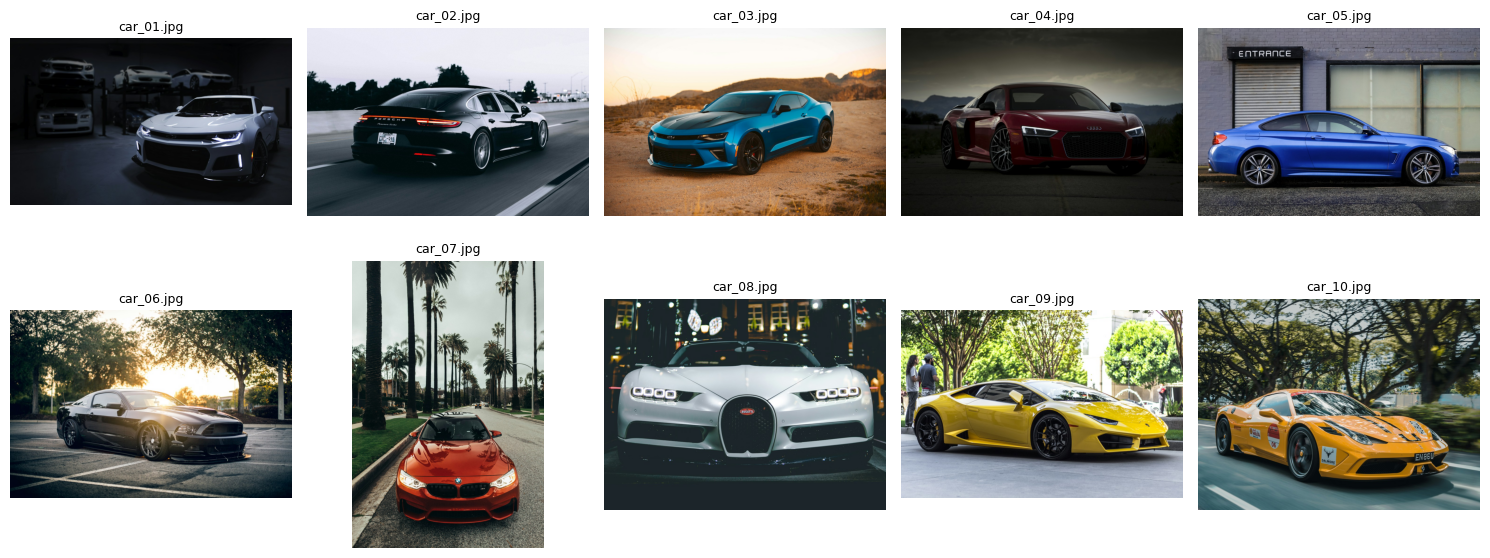

In [7]:
# Visualización del conjunto de datos
if valid_images:
    sample_paths = valid_images[: min(10, len(valid_images))]
    columns = 5
    rows = (len(sample_paths) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3 * rows))
    axes = axes.ravel() if hasattr(axes, "ravel") else [axes]

    for axis in axes:
        axis.axis("off")

    for axis, path in zip(axes, sample_paths):
        with Image.open(path) as img:
            axis.imshow(img.convert("RGB"))
        axis.set_title(path.name, fontsize=9)
        axis.axis("off")

    plt.tight_layout()
    plt.show()
else:
    print("No hay imágenes para mostrar. Carga primero el dataset.")

## 3. Carga de Stable Diffusion y configuración del scheduler

Como ya diche en el anterior proyecto, no me permite usar el modelo en concreto. He acabado usando `runwayml/stable-diffusion-v1-5`

In [9]:
MODEL_ID = "runwayml/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True,
)

pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(pipe.scheduler.config)
pipe = pipe.to(DEVICE)

# Optimizaciones de memoria compatibles con GPU
if DEVICE == "cuda":
    pipe.enable_attention_slicing()

print(f"Modelo cargado: {MODEL_ID}")
print(f"Scheduler: {pipe.scheduler.__class__.__name__}")

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Modelo cargado: runwayml/stable-diffusion-v1-5
Scheduler: EulerAncestralDiscreteScheduler


## 4. Generación de imágenes desde texto

In [10]:
NEGATIVE_PROMPT = (
    "blurry, low quality, distorted, deformed, duplicate, extra objects, "
    "bad anatomy, watermark, logo, text, cropped"
)

PROMPT_CONFIGS = [
    {
        "name": "coche_estudio",
        "prompt": (
            "A high-resolution commercial product photograph of a modern luxury sports car, "
            "three-quarter view, white seamless background, soft professional studio lighting, "
            "realistic metallic paint, glass and tyre textures, sharp focus, premium automotive advertising photography"
        ),
        "guidance_scale": 7.5,
        "num_inference_steps": 30,
        "seed": 101,
    },
    {
        "name": "coche_futurista",
        "prompt": (
            "Futuristic electric supercar with subtle neon blue accents, displayed on a dark reflective platform, "
            "cinematic cyberpunk lighting, dramatic atmosphere, detailed bodywork, realistic automotive photography"
        ),
        "guidance_scale": 9.0,
        "num_inference_steps": 40,
        "seed": 202,
    },
]

text_to_image_results = []

for config in PROMPT_CONFIGS:
    generator = torch.Generator(device="cuda" if DEVICE == "cuda" else "cpu").manual_seed(config["seed"])

    image = pipe(
        prompt=config["prompt"],
        negative_prompt=NEGATIVE_PROMPT,
        guidance_scale=config["guidance_scale"],
        num_inference_steps=config["num_inference_steps"],
        generator=generator,
        width=512,
        height=512,
    ).images[0]

    output_path = OUTPUT_DIR / f"{config['name']}.png"
    image.save(output_path)
    text_to_image_results.append((config, image, output_path))
    print(f"Guardada: {output_path}")

  0%|          | 0/30 [00:00<?, ?it/s]

Guardada: generated_images/coche_estudio.png


  0%|          | 0/40 [00:00<?, ?it/s]

Guardada: generated_images/coche_futurista.png


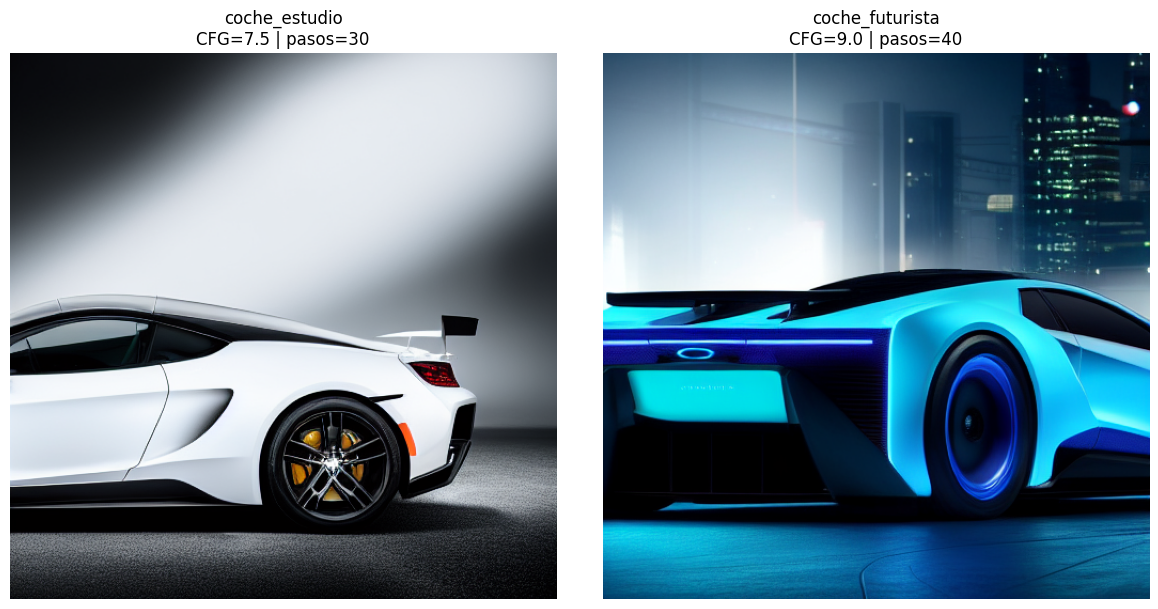

In [11]:
# Comparación de resultados text-to-image
if text_to_image_results:
    fig, axes = plt.subplots(1, len(text_to_image_results), figsize=(12, 6))
    if len(text_to_image_results) == 1:
        axes = [axes]

    for axis, (config, image, output_path) in zip(axes, text_to_image_results):
        axis.imshow(image)
        axis.set_title(
            f"{config['name']}\nCFG={config['guidance_scale']} | pasos={config['num_inference_steps']}"
        )
        axis.axis("off")

    plt.tight_layout()
    plt.show()

## 5. Preparación de la imagen base para image-to-image

Imagen base: custom_dataset/car_01.jpg


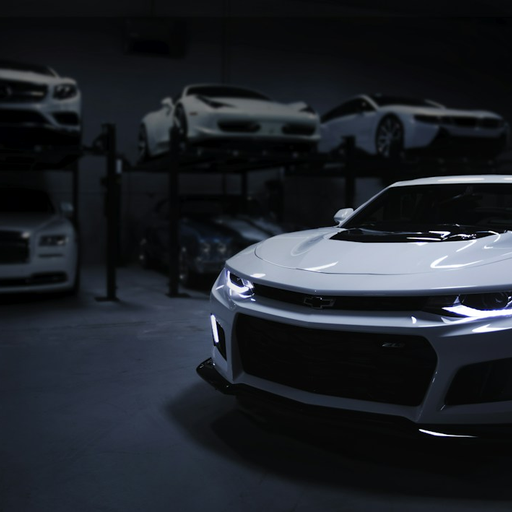

In [12]:
if not valid_images:
    raise FileNotFoundError(
        "No se encontró ninguna imagen válida en custom_dataset. "
        "Carga al menos una imagen antes de ejecutar image-to-image."
    )

BASE_IMAGE_PATH = valid_images[0]

with Image.open(BASE_IMAGE_PATH) as source:
    source = ImageOps.exif_transpose(source).convert("RGB")
    base_image = ImageOps.fit(
        source,
        (512, 512),
        method=Image.Resampling.LANCZOS,
        centering=(0.5, 0.5),
    )

print(f"Imagen base: {BASE_IMAGE_PATH}")
display(base_image)

## 6. Variaciones image-to-image


In [13]:
img2img_pipe = StableDiffusionImg2ImgPipeline(**pipe.components)
img2img_pipe = img2img_pipe.to(DEVICE)

if DEVICE == "cuda":
    img2img_pipe.enable_attention_slicing()

IMG2IMG_PROMPT = (
    "A futuristic premium version of this sports car, elegant neon blue accents, carbon fibre bodywork, "
    "dark studio background, realistic metallic materials, commercial automotive photography, sharp focus"
)

variation_configs = [
    {
        "name": "variacion_euler_strength_035",
        "scheduler": "Euler ancestral",
        "strength": 0.35,
        "guidance_scale": 7.5,
        "num_inference_steps": 30,
    },
    {
        "name": "variacion_euler_strength_075",
        "scheduler": "Euler ancestral",
        "strength": 0.75,
        "guidance_scale": 7.5,
        "num_inference_steps": 30,
    },
    {
        "name": "variacion_ddim_strength_060",
        "scheduler": "DDIM",
        "strength": 0.60,
        "guidance_scale": 7.5,
        "num_inference_steps": 30,
    },
]

variation_results = []

for config in variation_configs:
    if config["scheduler"] == "DDIM":
        img2img_pipe.scheduler = DDIMScheduler.from_config(img2img_pipe.scheduler.config)
    else:
        img2img_pipe.scheduler = EulerAncestralDiscreteScheduler.from_config(img2img_pipe.scheduler.config)

    generator = torch.Generator(device="cuda" if DEVICE == "cuda" else "cpu").manual_seed(303)

    result = img2img_pipe(
        prompt=IMG2IMG_PROMPT,
        negative_prompt=NEGATIVE_PROMPT,
        image=base_image,
        strength=config["strength"],
        guidance_scale=config["guidance_scale"],
        num_inference_steps=config["num_inference_steps"],
        generator=generator,
    ).images[0]

    output_path = VARIATIONS_DIR / f"{config['name']}.png"
    result.save(output_path)
    variation_results.append((config, result, output_path))
    print(f"Guardada: {output_path}")

  0%|          | 0/10 [00:00<?, ?it/s]

Guardada: variations/variacion_euler_strength_035.png


  0%|          | 0/22 [00:00<?, ?it/s]

Guardada: variations/variacion_euler_strength_075.png


  0%|          | 0/18 [00:00<?, ?it/s]

Guardada: variations/variacion_ddim_strength_060.png


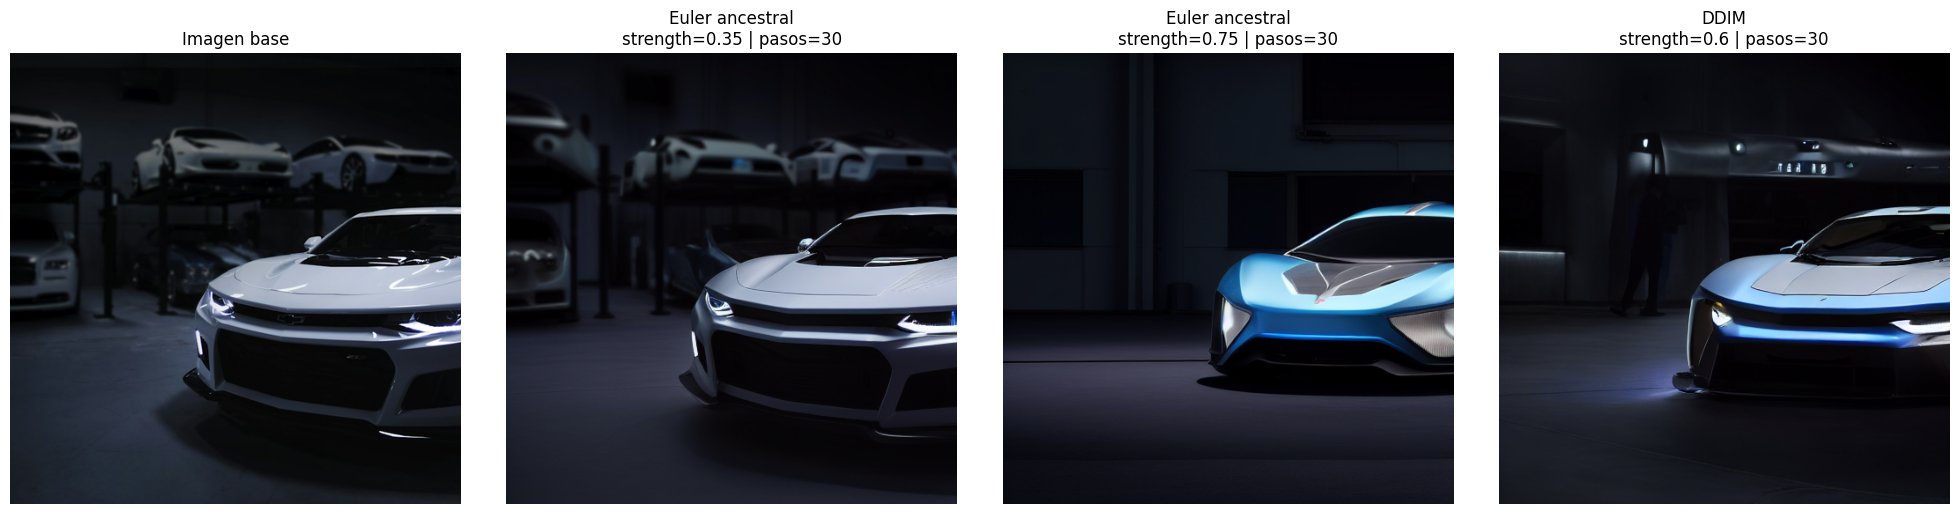

In [14]:
# Visualización: imagen original y variaciones
fig, axes = plt.subplots(1, 1 + len(variation_results), figsize=(5 * (1 + len(variation_results)), 5))

axes[0].imshow(base_image)
axes[0].set_title("Imagen base")
axes[0].axis("off")

for axis, (config, image, output_path) in zip(axes[1:], variation_results):
    axis.imshow(image)
    axis.set_title(
        f"{config['scheduler']}\nstrength={config['strength']} | pasos={config['num_inference_steps']}"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

## 7. Revisión de archivos generados

In [15]:
print("IMÁGENES TEXT-TO-IMAGE")
for path in sorted(OUTPUT_DIR.glob("*.png")):
    print(" -", path)

print("\nVARIACIONES IMAGE-TO-IMAGE")
for path in sorted(VARIATIONS_DIR.glob("*.png")):
    print(" -", path)

IMÁGENES TEXT-TO-IMAGE
 - generated_images/coche_estudio.png
 - generated_images/coche_futurista.png

VARIACIONES IMAGE-TO-IMAGE
 - variations/variacion_ddim_strength_060.png
 - variations/variacion_euler_strength_035.png
 - variations/variacion_euler_strength_075.png
